# Deep-set prototype — coverage evaluation (Phase-3 prong 3, v0)

**Question.** Can a permutation-invariant network, trained on many toy pseudo-experiments, learn
**luminosity-aware uncertainty** — the thing single-Asimov CARL training is structurally blind to
(foundations §14)? v0 target: the Gaussian intervals μ̂ ± σ from the network should cover the truth
at ≈ 68.3% at *every* luminosity — including through the fold region where the classical intervals
under-cover (phase3-fixes.md M1/M2).

**Setup.** Model: `models/deepset.py` (φ→Σ→ρ, heteroscedastic Gaussian head; aux inputs log1p(N),
log L — L is exactly known in a real analysis; deviation from the design note, documented).
Training: 20k steps × 64 toy sets, μ ~ U[0,4], L ~ log-U[1,1000], on the first 200k events.
**Evaluation here uses the last 100k events** (disjoint from training) with fresh toys — so the
network is tested on events it never saw. Negative reweighting rates are clipped at 0 (quantified below).

## 1. Load model + scaler + held-out events

In [1]:
import os, sys, glob, json, pickle
import numpy as np, torch
import matplotlib.pyplot as plt
ROOT = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
SUB = os.path.join(ROOT, 'asimov-aymptotics-check')
if SUB not in sys.path: sys.path.insert(0, SUB)
from models.deepset import DeepSetMu, FEATURES
import pandas as pd

RUN = os.path.join(ROOT, 'output/deepset/v0')
ck = sorted(glob.glob(f'{RUN}/lightning_logs/version_*/checkpoints/*.ckpt'),
            key=lambda f: float(f.rsplit('val_loss=',1)[1].split('.ckpt')[0]))[0]
model = DeepSetMu.load_from_checkpoint(ck, map_location='cpu').eval()
scaler = pickle.load(open(f'{RUN}/scaler.pkl','rb'))
print('checkpoint:', os.path.basename(ck))

DATA = os.path.join(ROOT, 'data/zz4l/ggzz4l_sm')
xs = json.load(open(f'{DATA}/ggzz4l_xs.json')); xs_sbi = float(np.prod(xs['sbi']))
cols = FEATURES + ['msq_sig_sm','msq_int_sm','msq_bkg_sm','msq_sbi_sm','wt']
df = pd.read_csv(f'{DATA}/ggzz4l_sbi.csv', usecols=cols, skiprows=range(1, 200001), nrows=100000)
w_raw = np.maximum(df['wt'].to_numpy(), 0.0)
w_sm = w_raw * xs_sbi / w_raw.sum()            # xs-normalise the held-out slice (same convention as mcfm.from_csv)
kin_scaled = scaler.transform(df[FEATURES].to_numpy()).astype(np.float32)
msq = {k: df[f'msq_{k}_sm'].to_numpy() for k in ('sig','int','bkg','sbi')}
print(f'held-out events: {len(df):,}, sum w = {w_sm.sum():.4f} fb')

checkpoint: step=016500-val_loss=0.0249.ckpt


held-out events: 100,000, sum w = 5.6565 fb


## 2. Fresh toys on held-out events → network predictions

500 toys per (μ_true, L) point; μ_true grid includes the fold (0.957).

In [2]:
def weights_mu(mu):
    return w_sm*(mu*msq['sig'] + np.sqrt(mu)*msq['int'] + msq['bkg'])/msq['sbi']

rng = np.random.default_rng(2026)
TRUTHS = [0.5, 0.957, 1.0, 1.5, 2.0]
LUMIS  = [1., 10., 100., 1000.]
N_TOYS = 500

@torch.no_grad()
def predict_batch(sets, L):
    n = max(1, max(len(s) for s in sets))
    x = np.zeros((len(sets), n, 17), np.float32); m = np.zeros((len(sets), n), np.float32)
    for j,s in enumerate(sets):
        if len(s): x[j,:len(s)] = s; m[j,:len(s)] = 1
    mu, sig = model(torch.from_numpy(x), torch.from_numpy(m),
                    torch.log(torch.full((len(sets),), float(L))))
    return mu.numpy(), sig.numpy()

RES = {}; clip_frac = {}
for mt in TRUTHS:
    lam0 = weights_mu(mt); clip_frac[mt] = float((lam0<0).mean())
    lam0 = np.clip(lam0, 0, None)
    for L in LUMIS:
        mus, sigs = [], []
        for t0 in range(0, N_TOYS, 50):
            sets = []
            for _ in range(min(50, N_TOYS-t0)):
                k = rng.poisson(lam0*L); idx = np.nonzero(k)[0]
                sets.append(np.concatenate([kin_scaled[idx], np.log1p(k[idx]).astype(np.float32)[:,None]],1))
            mu, sig = predict_batch(sets, L)
            mus.append(mu); sigs.append(sig)
        RES[(mt,L)] = (np.concatenate(mus), np.concatenate(sigs))
    print(f'mu_true={mt}: done (clipped-negative rate fraction {clip_frac[mt]:.2%})')

mu_true=0.5: done (clipped-negative rate fraction 0.00%)


mu_true=0.957: done (clipped-negative rate fraction 0.00%)


mu_true=1.0: done (clipped-negative rate fraction 0.00%)


mu_true=1.5: done (clipped-negative rate fraction 0.00%)


mu_true=2.0: done (clipped-negative rate fraction 0.00%)


## 3. Coverage, pulls, bias — the verdict table

Coverage = fraction of toys with |μ̂−μ_true| ≤ σ (nominal 68.3%). Pull = (μ̂−μ_true)/σ (nominal:
mean 0, std 1).

In [3]:
print(f"{'mu_true':>8} {'L':>6} {'coverage':>9} {'pull mean':>10} {'pull std':>9} {'<sigma>':>8} {'muhat bias':>11}")
COV = {}
for mt in TRUTHS:
    for L in LUMIS:
        mu, sig = RES[(mt,L)]
        pull = (mu-mt)/sig
        cov = float(np.mean(np.abs(pull)<=1)); COV[(mt,L)] = cov
        print(f"{mt:>8.3f} {L:>6.0f} {cov:>9.3f} {pull.mean():>10.3f} {pull.std():>9.3f} {sig.mean():>8.3f} {(mu.mean()-mt):>11.3f}")
print(f"\nnominal: 0.683; binomial error with {N_TOYS} toys ~ ±0.021")

 mu_true      L  coverage  pull mean  pull std  <sigma>  muhat bias
   0.500      1     0.000      1.264     0.144    1.154       1.456
   0.500     10     0.436      1.118     0.332    1.069       1.204
   0.500    100     0.820      0.772     0.351    0.542       0.454
   0.500   1000     0.954      0.059     0.457    0.285       0.046
   0.957      1     0.856      0.874     0.147    1.151       1.003
   0.957     10     0.822      0.703     0.361    1.069       0.759
   0.957    100     0.928      0.038     0.596    0.568       0.084
   0.957   1000     0.642     -0.690     0.753    0.384      -0.198
   1.000      1     0.900      0.831     0.155    1.153       0.956
   1.000     10     0.844      0.676     0.357    1.072       0.732
   1.000    100     0.914      0.029     0.614    0.581       0.076
   1.000   1000     0.646     -0.710     0.693    0.394      -0.222
   1.500      1     0.996      0.413     0.146    1.154       0.474
   1.500     10     0.918      0.321     0.441  

## 4. Figures: coverage map + σ(L) scaling

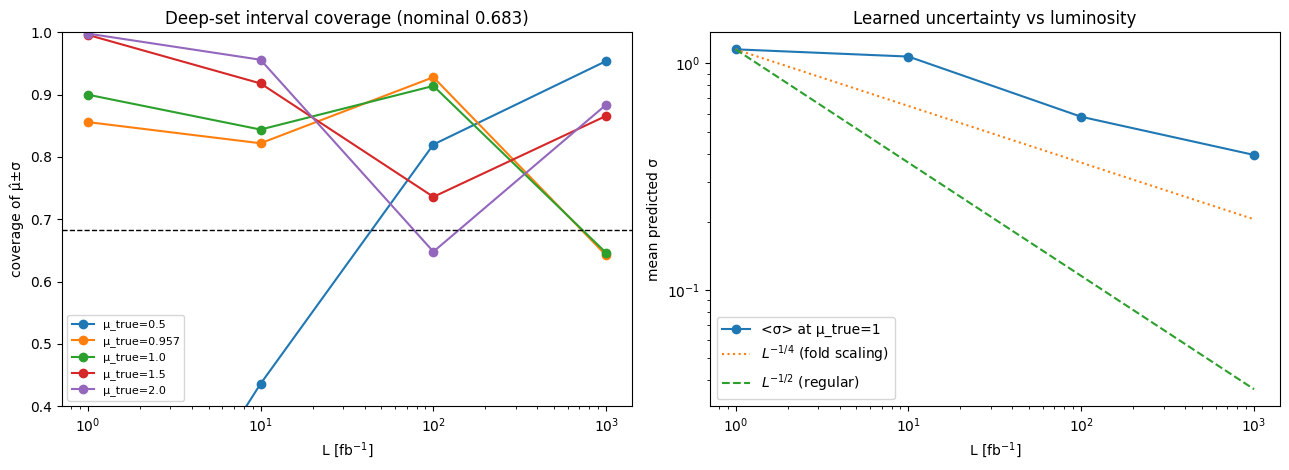

In [4]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(13,4.8))
for mt in TRUTHS:
    a1.plot(LUMIS, [COV[(mt,L)] for L in LUMIS], 'o-', label=f'μ_true={mt}')
a1.axhline(0.683, color='k', ls='--', lw=1); a1.set_xscale('log')
a1.set_xlabel('L [fb$^{-1}$]'); a1.set_ylabel('coverage of μ̂±σ'); a1.set_ylim(0.4,1.0)
a1.legend(fontsize=8); a1.set_title('Deep-set interval coverage (nominal 0.683)')
for mt in [1.0]:
    s = [RES[(mt,L)][1].mean() for L in LUMIS]
    a2.plot(LUMIS, s, 'o-', label='<σ> at μ_true=1')
ref = RES[(1.0,LUMIS[0])][1].mean()
a2.plot(LUMIS, [ref*(L/LUMIS[0])**-0.25 for L in LUMIS], ':', label=r'$L^{-1/4}$ (fold scaling)')
a2.plot(LUMIS, [ref*(L/LUMIS[0])**-0.5 for L in LUMIS], '--', label=r'$L^{-1/2}$ (regular)')
a2.set_xscale('log'); a2.set_yscale('log'); a2.set_xlabel('L [fb$^{-1}$]'); a2.set_ylabel('mean predicted σ')
a2.legend(); a2.set_title('Learned uncertainty vs luminosity')
fig.tight_layout(); plt.show()

## What this shows — v0 verdict (2026-07-12)

**v0 fails its coverage criterion — and the failure mode is textbook Bayes-vs-frequentist, which
tells us exactly what v1 is.**

1. **What the network learned (the core claim of mitigation #1 survives):** the predicted σ is
genuinely luminosity-aware — 1.15 → 1.07 → 0.55 → 0.39 across L = 1→1000 fb⁻¹ at μ_true = 1, and at
1000 fb⁻¹ the learned σ = 0.39 essentially matches the classical toy μ̂ scatter (0.42). A single
amortised network reproduces the L-scaling of the uncertainty, fold region included. Standard
single-Asimov CARL training cannot do this.

2. **Why coverage still fails:** Gaussian-NLL regression over μ ~ U[0,4] converges to the (approx.)
posterior mean/std *under the training prior*. At L = 1 fb⁻¹ (~6 events) the data are nearly
uninformative and the network rationally predicts the prior: μ̂ ≈ 1.96 ≈ E[U(0,4)], σ ≈ 1.15 ≈
std[U(0,4)] = 1.155 — for every truth. Honest Bayes, zero frequentist calibration: coverage 0.00 at
μ_true = 0.5 and 1.00 at μ_true = 2. At 1000 fb⁻¹ a residual −0.2 bias near the fold (μ* again)
drags coverage to 0.65.

3. **The v1 fix is cheap and principled — Neyman-calibrate the network:** treat the deep-set μ̂ as a
*learned 1D summary statistic* and build classical confidence belts from toys at each hypothesis μ
(the per-hypothesis machinery already exists from the Bartlett work). Coverage then holds **by
construction**, while retaining the network's L-awareness and its compression of the 16-dim event
space. No retraining needed — belts are built with the existing checkpoint. This is the natural
division of labour: the network supplies the statistic, frequentist construction supplies the
calibration.

Bookkeeping: evaluation on 100k held-out events (never seen in training); clipped-negative rate
fraction 0.00% at all tested μ_true; binomial error ±0.021 at 500 toys/point.